# Module 32: the evaluation harness, and how to score a failure-region method

**Theory:** course Module 32 (metrics, answer key, seeds, ablations). This notebook builds the shared harness `failreg/`
that notebooks 13, 14, 15 and 17 reuse, then runs a small benchmark with it. It ends with one esmini cut-in case.
CPU only, about two minutes.

The harness: `problems.py` (test functions with a known failure region), `metrics.py`, `designs.py` (baselines),
`models.py`, `acquisition.py`, `replication.py`, `loop.py` (seeds, search loop) and `esmini_case.py`.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
HERE = Path.cwd().resolve()
HERE = HERE if (HERE / "failreg").exists() else HERE / "notebooks/course"
sys.path.insert(0, str(HERE))
from failreg import problems as P, metrics as M, designs as D, models as MD, acquisition as A, replication as R, loop as L, plots as PL
warnings.filterwarnings("ignore")
PL.style(); T0 = time.time()

## 1. Test problems with a known answer

A method can only be scored where the true region is known (Module 32, §1). All problems live on [0, 1]². A run returns a
margin; it fails when the margin is below the threshold.

| Problem | Failure region | Why it is here |
|---|---|---|
| `branin` | Branin-Hoo ≤ 10 | three disconnected regions |
| `four_branch` | four-branch series system ≤ 0 (inputs mapped from [−5, 5]²) | four regions, a standard reliability benchmark (Bect et al. 2012 use it) |
| `car` | minimum gap d₀ − Δv·t_r − Δv²/(2a) < 0 | a car-following stop with a zero contour in closed form |
| `noisy_car` | the same with noise sd 0.5–6.5 m rising with closing speed; target p(x) ≥ 0.10 | input-dependent noise |

branin       failure share 0.159, regions 3
four_branch  failure share 0.580, regions 4
car          failure share 0.305, regions 1
noisy_car    failure share 0.382, regions 1


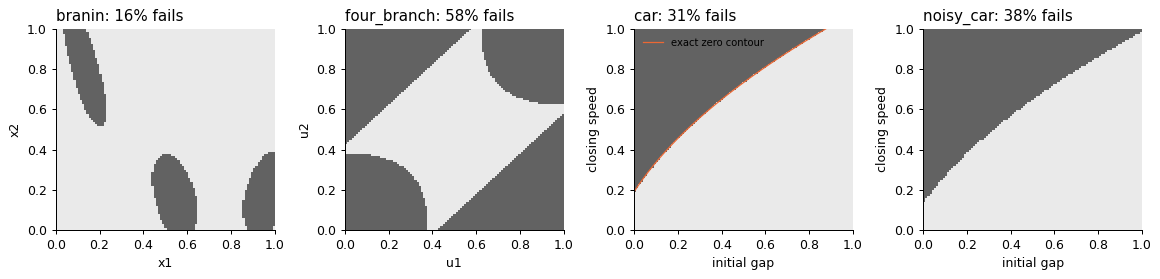

grid boundary vs exact contour, max distance: 0.0105 (grid step 0.01)


In [2]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, name in zip(axs, P.ALL):
    p = P.get(name); G, truth, shape, _ = p.test
    PL.region_map(ax, p, title=f"{name}: {truth.mean():.0%} fails")
    print(f"{name:12s} failure share {truth.mean():.3f}, regions {M.regions(truth, shape)[1]}")
c = P.car_zero_contour(); axs[2].plot(c[:, 0], c[:, 1], color=PL.ORANGE, lw=1, label="exact zero contour"); axs[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
p = P.get("car"); G, t, sh, _ = p.test
print("grid boundary vs exact contour, max distance:", round(M.boundary_distance(c, M.boundary_points(t, sh))["max"], 4), "(grid step 0.01)")

## 2. The metrics

Positive = failing. The table follows Module 32, §2.

| Metric | Function | Needs the answer key? |
|---|---|---|
| false-safe rate (failing predicted safe / failing) | `M.region_scores` | yes |
| false-unsafe rate (safe predicted failing / safe) | `M.region_scores` | yes |
| misclassified share of a dense grid | `M.region_scores` | yes |
| boundary distance, mean and max (Batsch et al. 2019 report the max) | `M.boundary_distance` | yes |
| runs to target | `M.runs_to_target` | yes |
| calibration: band coverage at stated levels | `M.calibration` | no, if held-out reruns are used |
| distinct mechanisms found | `M.mechanisms_found` | yes |
| undecided share (0.05 < P < 0.95) and wall-clock | `M.undecided`, `loop` | no |

One accuracy number hides which error was made. The constant predictor "everything passes" shows it:

In [3]:
p = P.get("branin")
rows = {"constant: everything passes": L.static(p, D.sobol, 16, 0, lambda: MD.Constant(100.0))[0][-1],
        "GP on 16 Sobol runs": L.static(p, D.sobol, 16, 0, lambda: MD.GPR())[0][-1]}
keys = ["misclassified", "false_safe", "false_unsafe", "balanced_accuracy", "boundary_mean", "boundary_max"]
print(f"{'':30s}" + "".join(f"{k:>18s}" for k in keys))
for name, r in rows.items():
    print(f"{name:30s}" + "".join(f"{r[k]:18.3f}" for k in keys))

                                   misclassified        false_safe      false_unsafe balanced_accuracy     boundary_mean      boundary_max
constant: everything passes                0.159             1.000             0.000             0.500               inf               inf
GP on 16 Sobol runs                        0.121             0.614             0.028             0.679             0.055             0.313


The constant predictor's error is entirely false-safe, and it predicts no boundary at all (distance = inf). Report it first, as a
control.

## 3. A benchmark: GP active learning against Sobol and random at equal budget

Arms (Module 32, Figure 1): GP with the straddle criterion (notebook 15), the same GP on a Sobol design, and on uniform
random points. 60 runs, 10 seeds. Seeds are paired: on each seed the GP-AL arm starts from the Sobol arm's first 10 points and
all arms share the replicate stream.

59 s


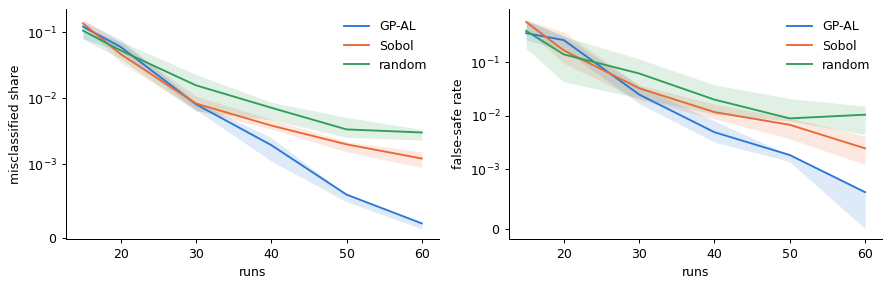

In [4]:
p = P.get("branin"); NS = [15, 20, 30, 40, 50, 60]; SEEDS = range(10)
gp = lambda: MD.GPR()
H = {"GP-AL": [], "Sobol": [], "random": []}; RUNS_AL = []
t = time.time()
for s in SEEDS:
    h, X, y, _ = L.active(p, gp, L.by_score(A.straddle), 60, s, n0=10, batch=5, checkpoints=NS); H["GP-AL"].append(h); RUNS_AL.append((X, y))
    H["Sobol"].append(L.static(p, D.sobol, 60, s, gp, NS)[0])
    H["random"].append(L.static(p, D.random, 60, s, gp, NS)[0])
print(f"{time.time() - t:.0f} s")
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3))
PL.curves(axs[0], NS, {a: [[r["misclassified"] for r in h] for h in H[a]] for a in H}, "misclassified share", logy=True)
PL.curves(axs[1], NS, {a: [[r["false_safe"] for r in h] for h in H[a]] for a in H}, "false-safe rate", logy=True)
plt.tight_layout(); plt.show()

Report the median and the spread over seeds, and an interval for an aggregate. The interquartile mean (IQM) with a
bootstrap interval follows Agarwal et al. 2021, who warn that point estimates over few runs ignore the uncertainty of a
finite number of runs.

In [5]:
n = 60
print(f"at {n} runs, misclassified share in %   median [IQR]        IQM [95% bootstrap CI]")
for a in H:
    v = 100 * L.table(H[a], "misclassified", n); s = M.summary(v); lo, hi = M.bootstrap_ci(v)
    print(f"  {a:8s}  {s['median']:6.3f} [{s['q25']:.3f}, {s['q75']:.3f}]    {s['iqm']:6.3f} [{lo:.3f}, {hi:.3f}]")
pairs = [("GP-AL", "Sobol"), ("GP-AL", "random"), ("Sobol", "random")]
pv = [M.paired_test(L.table(H[a], "misclassified", n), L.table(H[b], "misclassified", n)) for a, b in pairs]
for (a, b), p_raw, p_adj in zip(pairs, pv, M.holm(pv)):
    wins = int(np.sum(L.table(H[a], "misclassified", n) < L.table(H[b], "misclassified", n)))
    print(f"  {a} vs {b}: {a} better on {wins}/10 seeds, Wilcoxon p = {p_raw:.4f}, Holm p = {p_adj:.4f}")

at 60 runs, misclassified share in %   median [IQR]        IQM [95% bootstrap CI]
  GP-AL      0.020 [0.012, 0.020]     0.018 [0.013, 0.025]
  Sobol      0.123 [0.096, 0.154]     0.126 [0.098, 0.158]


  random     0.304 [0.233, 0.338]     0.296 [0.212, 0.578]
  GP-AL vs Sobol: GP-AL better on 10/10 seeds, Wilcoxon p = 0.0020, Holm p = 0.0059
  GP-AL vs random: GP-AL better on 10/10 seeds, Wilcoxon p = 0.0020, Holm p = 0.0059
  Sobol vs random: Sobol better on 9/10 seeds, Wilcoxon p = 0.0059, Holm p = 0.0059


## 4. Runs to target: the target changes the ranking

Runs until the misclassified share first stays at or below a target. Active learning spends its first runs on the same Sobol
points, so at a loose target the arms tie (or Sobol wins, as in the GP demo of Module 32, §4); only a tight target
separates them here. Report several targets.

In [6]:
for target in (0.02, 0.005, 0.001):
    row = {a: np.median([M.runs_to_target(NS, [r["misclassified"] for r in h], target) for h in H[a]]) for a in H}
    print(f"target {100*target:5.1f} %: " + ", ".join(f"{a} {v:.0f}" for a, v in row.items()))

target   2.0 %: GP-AL 30, Sobol 30, random 30
target   0.5 %: GP-AL 40, Sobol 40, random 50
target   0.1 %: GP-AL 50, Sobol inf, random inf


## 5. Calibration

Does the stated band hold? Coverage above the level is conservative, below it is overconfident. Coverage of the true margin by the GP's central bands, on the test grid near the boundary
(|f − τ| < 5). Then the field version, which needs no answer key: on `noisy_car`, the share of held-out new runs inside
the predictive band μ ± z·√(σ² + r).

In [7]:
G, truth, shape, _ = p.test
near = np.abs(p.f(G) - p.tau) < 5
cov = []
for X, y in RUNS_AL:
    m = MD.GPR().fit(X, y); mu, sd = m.predict(G[near]); cov.append(M.calibration(mu, sd, p.f(G[near])))
print("branin, GP-AL at 60 runs, coverage of the true margin:", {q: round(np.median([c[q] for c in cov]), 3) for q in cov[0]})

q = P.get("noisy_car"); rng = np.random.default_rng(L.seed_of("heldout"))
X = D.sobol(64, 2, 1); m = MD.GPR().fit(X, q.run(X, rng))
Xh = D.random(400, 2, 7); yh = q.run(Xh, rng); mu, sd = m.predict(Xh)
print("noisy_car, GP on 64 runs, coverage of held-out runs:", {k: round(v, 3) for k, v in M.calibration(mu, np.sqrt(sd**2 + m.noise_var), yh).items()},
      "(constant noise fitted where the true noise varies)")

branin, GP-AL at 60 runs, coverage of the true margin: {0.5: 0.93, 0.8: 0.998, 0.95: 1.0}


noisy_car, GP on 64 runs, coverage of held-out runs: {0.5: 0.547, 0.8: 0.78, 0.95: 0.875} (constant noise fitted where the true noise varies)


## 6. Distinct mechanisms

On `four_branch` the question is whether all four regions are found. A region counts as found when at least 20 % of its
cells are predicted failing. A method that misses a region shows it here even when its misclassified share is low.

In [8]:
p4 = P.get("four_branch"); res = {"GP-AL": [], "Sobol": []}
G4, t4, sh4, _ = p4.test
for s in range(5):
    _, X, y, m = L.active(p4, gp, L.by_score(A.straddle), 40, s, n0=10, batch=5)
    res["GP-AL"].append(M.mechanisms_found(t4, L.region(p4, m, G4), sh4)[0])
    Xs = D.sobol(40, 2, L.seed_of("design", s)); ms = L.fit(p4, gp, Xs, p4.run(Xs, np.random.default_rng(s)))
    res["Sobol"].append(M.mechanisms_found(t4, L.region(p4, ms, G4), sh4)[0])
print("regions found of 4 at 40 runs, per seed:", res)

regions found of 4 at 40 runs, per seed: {'GP-AL': [4, 4, 4, 4, 4], 'Sobol': [4, 4, 4, 4, 4]}


## 7. Ablation: remove one part at a time

Remove the adaptivity (= the Sobol arm above) or remove the model (1-nearest-neighbour on the same runs). The rule from
Module 32: a component that adds nothing is reported as such. The last row (1-NN on Sobol runs) is a reference, not an
ablation: compare it with the 1-NN row on the GP-AL runs. Adaptive designs bunch near the boundary and pay off only with a
model that interpolates smoothly. With 10 seeds, the smallest possible two-sided Wilcoxon p is 0.002 (0.006 after Holm
over three tests).

In [9]:
knn_al = []; knn_sobol = []
G, truth, shape, _ = p.test
for s, (X, y) in zip(SEEDS, RUNS_AL):
    knn_al.append(M.region_scores(truth, L.region(p, MD.NearestNeighbour().fit(X, y), G))["misclassified"])
    Xs = D.sobol(60, 2, L.seed_of("design", s)); ys = p.run(Xs, np.random.default_rng(L.seed_of("rep", p.name, s)))
    knn_sobol.append(M.region_scores(truth, L.region(p, MD.NearestNeighbour().fit(Xs, ys), G))["misclassified"])
full = L.table(H["GP-AL"], "misclassified", 60)
abl = {"without adaptivity (GP on Sobol)": L.table(H["Sobol"], "misclassified", 60), "without the GP (1-NN on GP-AL runs)": np.array(knn_al),
       "1-NN on Sobol runs": np.array(knn_sobol)}
pv = M.holm([M.paired_test(full, v) for v in abl.values()])
for (name, v), pa in zip(abl.items(), pv):
    verdict = "the removed part helps" if pa < 0.05 and np.median(v) > np.median(full) else "the removed part adds nothing measurable here"
    print(f"{name:38s} median {100*np.median(v):.3f} % vs full {100*np.median(full):.3f} %, Holm p = {pa:.4f}: {verdict}")

without adaptivity (GP on Sobol)       median 0.123 % vs full 0.020 %, Holm p = 0.0059: the removed part helps


without the GP (1-NN on GP-AL runs)    median 17.621 % vs full 0.020 %, Holm p = 0.0059: the removed part helps
1-NN on Sobol runs                     median 8.548 % vs full 0.020 %, Holm p = 0.0059: the removed part helps


## 8. Field metrics

On a real system there is no answer key; the undecided share, run counts and wall-clock remain.

In [10]:
for a in H:
    u = [h[-1]["undecided"] for h in H[a]]
    w = [h[-1]["wall_s"] if "wall_s" in h[-1] else h[-1]["fit_s"] for h in H[a]]   # static arms: one fit at the end
    print(f"{a:8s} undecided share at 60 runs {np.median(u):.4f}, median wall-clock {np.median(w):.2f} s (model fits included)")

GP-AL    undecided share at 60 runs 0.0026, median wall-clock 2.68 s (model fits included)
Sobol    undecided share at 60 runs 0.0175, median wall-clock 0.37 s (model fits included)
random   undecided share at 60 runs 0.0246, median wall-clock 0.33 s (model fits included)


## 9. esmini cut-in

The same scoring on the repo's simulator: esmini's ACC ego against a scripted cut-in at 30 m/s (`src/stp/cutin`), over
gap at cut-in and relative speed; fail = minimum TTC below 1.5 s. The answer key is the committed dense reference grid
(`results/gp_boundary/reference_grid.npz`). GP-AL against Sobol at 60 runs, 3 seeds.

360 esmini runs in 22 s
GP-AL  misclassified % at [20, 40, 60]:  [1.35, 0.44, 0.17]  false-safe at 60: 0.011
Sobol  misclassified % at [20, 40, 60]:  [2.13, 2.16, 1.76]  false-safe at 60: 0.073


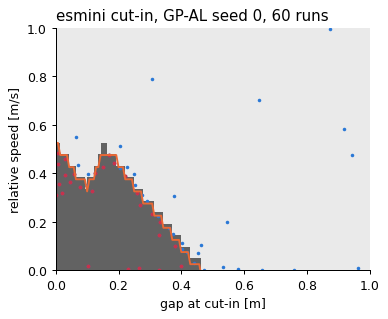

In [11]:
from failreg import esmini_case as E
ec = E.cutin(); NE = [20, 40, 60]; HE = {"GP-AL": [], "Sobol": []}
t = time.time()
for s in range(3):
    h, X, y, m = L.active(ec, gp, L.by_score(A.straddle), 60, s, n0=10, batch=5, checkpoints=NE); HE["GP-AL"].append(h)
    if s == 0: keep = (X, y, m)
    HE["Sobol"].append(L.static(ec, D.sobol, 60, s, gp, NE)[0])
print(f"{ec.calls} esmini runs in {time.time() - t:.0f} s")
for a in HE:
    print(f"{a:6s} misclassified % at {NE}: ", [round(100 * np.median(L.table(HE[a], 'misclassified', n)), 2) for n in NE],
          " false-safe at 60:", round(np.median(L.table(HE[a], 'false_safe', 60)), 3))
X, y, m = keep; G, truth, shape, ok = ec.test
fig, ax = plt.subplots(figsize=(4.5, 3.5))
PL.region_map(ax, ec, pred=L.region(ec, m, G), X=X, Xfail=X[y < 0], title="esmini cut-in, GP-AL seed 0, 60 runs"); plt.show()

## References

- H. Tu, S. Suo, L. Zhang, K. Wong, R. Urtasun, "Towards Scalable Coverage-Based Testing of Autonomous Vehicles," CoRL 2023 (balanced accuracy, error recall, ablations).
- F. Batsch, A. Daneshkhah, M. Cheah, S. Kanarachos, A. Baxendale, "Performance Boundary Identification for the Evaluation of Automated Vehicles using Gaussian Process Classification," IEEE ITSC 2019, arXiv:1907.05364 (maximum distance between boundary estimates).
- M. Li, T. Chen, X. Yao, "How to Evaluate Solutions in Pareto-based Search-Based Software Engineering? A Critical Review and Methodological Guidance," IEEE TSE 2020 (reference-set metrics need a reference).
- R. Agarwal, M. Schwarzer, P. S. Castro, A. Courville, M. G. Bellemare, "Deep Reinforcement Learning at the Edge of the Statistical Precipice," NeurIPS 2021, arXiv:2108.13264 (IQM, bootstrap intervals).
- G. Klees, A. Ruef, B. Cooper, S. Wei, M. Hicks, "Evaluating Fuzz Testing," CCS 2018, arXiv:1808.09700 (repeated trials and statistical tests).
- X. Lyu, M. Binois, M. Ludkovski, "Evaluating Gaussian Process Metamodels and Sequential Designs for Noisy Level Set Estimation," Statistics and Computing 31, 2021 (many macro-runs per design).
- J. Bect, D. Ginsbourger, L. Li, V. Picheny, E. Vazquez, "Sequential design of computer experiments for the estimation of a probability of failure," Statistics and Computing 22, 2012, arXiv:1009.5177 (four-branch test case).

In [12]:
print(f"notebook ran in {time.time() - T0:.0f} s")

notebook ran in 96 s
